# Étape 6 — Phase B : diversité d'ensemble

**Constat Phase A** : meilleure recette val = `ENS_0.4F1+0.6F2_TTA` à **0.001029** 

Plan Phase B — entraîner 2 nouveaux modèles complémentaires :

- M3 = convnext_tiny seed=1
- M4 = efficientnet_b3


## 1. Setup 

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd()   # racine du depot (les notebooks sont a la racine)
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm
from torch.utils.data import DataLoader

from dc_utils.paths import IMAGE_DIR, ARTIFACTS_DIR
from dc_utils.training import TrainConfig, train_model, OcclusionDataset, default_eval_tf
from dc_utils.metric import compute_score

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device =', device, '| timm', timm.__version__, '| torch', torch.__version__)

EXP_DIR = ROOT / 'experiments'
df_train = pd.read_csv(ROOT / 'data' / 'train_split.csv')
df_val   = pd.read_csv(ROOT / 'data' / 'val_split.csv')
print('train:', len(df_train), '| val:', len(df_val))

# Mêmes définitions qu'étape 4
class TimmRegressor(nn.Module):
    def __init__(self, backbone_name: str, pretrained: bool = True, bias_init: float | None = None):
        super().__init__()
        self.backbone = timm.create_model(backbone_name, pretrained=pretrained, num_classes=1)
        if bias_init is not None:
            head = self.backbone.get_classifier()
            with torch.no_grad():
                head.bias.fill_(bias_init); head.weight.mul_(0.01)
    def forward(self, x):
        return torch.sigmoid(self.backbone(x)).squeeze(-1)

_p0 = float(df_train['FaceOcclusion'].mean())
HEAD_BIAS_INIT = float(np.log(_p0 / (1.0 - _p0)))
print(f'mean target = {_p0:.4f}  ->  bias_init = logit(p0) = {HEAD_BIAS_INIT:.4f}')

def fresh_model(backbone_name: str, seed: int = 42, bias_init: float | None = HEAD_BIAS_INIT):
    torch.manual_seed(seed); np.random.seed(seed)
    m = TimmRegressor(backbone_name, bias_init=bias_init).to(device)
    n = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f'{backbone_name} (seed={seed}): {n/1e6:.2f}M params | bias_init={bias_init:.3f}')
    return m

RESULTS: list[dict] = []
def log_run(name, history, best, notes=''):
    history.to_csv(EXP_DIR / f'history_{name}.csv', index=False)
    RESULTS.append({'name': name, 'best_epoch': best['epoch'], 'val_score': best['score'],
                    'err_F': best['err_F'], 'err_M': best['err_M'], 'gap': best['gap'], 'notes': notes})
    print(f'\n>>> {name}: val_score = {best["score"]:.5f} (epoch {best["epoch"]})\n')


<repo>/.venv/lib64/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device = cuda | timm 1.0.27 | torch 2.12.0+cu130
train: 89793 | val: 9977
mean target = 0.0827  ->  bias_init = logit(p0) = -2.4069


## 2. M3 — convnext_tiny seed=1

In [ ]:
import time
from torch.utils.data import DataLoader
from dc_utils.training import _IMG_ARRAY, _IMG_INDEX, OcclusionDatasetRAM, default_train_tf

if _IMG_ARRAY is None:
    print('Cache vide -> sera rempli au 1er train_model(cache_in_ram=True)')
else:
    print(f'Cache : shape {_IMG_ARRAY.shape} | {_IMG_ARRAY.nbytes/1e9:.2f} GB | {len(_IMG_INDEX)} entrées')

Cache vide -> sera rempli au 1er train_model(cache_in_ram=True)


In [ ]:
model = fresh_model('convnext_tiny', seed=1)

cfg = TrainConfig(epochs=8, lr=1e-4, weight_decay=1e-4, batch_size=64, use_amp=True,
                  num_workers=4, cache_in_ram=True)
hist, best = train_model(
    model, df_train, df_val, IMAGE_DIR, cfg, device,
    save_path=ARTIFACTS_DIR / 'exp_M3_convnext_seed1.pt', log_prefix='[M3] ',
)
log_run('M3_convnext_seed1', hist, best, notes='convnext_tiny, seed=1, 8ep, BS=64, 3090/AMP, RAM cache')

convnext_tiny (seed=1): 27.82M params | bias_init=-2.407


decode 99770 imgs: 100%|██████████| 99770/99770 [01:31<00:00, 1085.42it/s]


  -> RAM cache: shape (99770, 224, 224, 3) | dtype uint8 | 15.02 GB (single ndarray, fork-safe)


[M3] ep 1 | loss 0.00203 | score 0.00165 | err_F 0.00114 | err_M 0.00148 | gap 0.00034 | 145s *


[M3] ep 2 | loss 0.00129 | score 0.00192 | err_F 0.00113 | err_M 0.00166 | gap 0.00053 | 139s


...

[M3] ep 4 | loss 0.00074 | score 0.00158 | err_F 0.00080 | err_M 0.00132 | gap 0.00052 | 139s


[M3] ep 5 | loss 0.00057 | score 0.00123 | err_F 0.00053 | err_M 0.00099 | gap 0.00046 | 141s *


[M3] ep 6 | loss 0.00045 | score 0.00116 | err_F 0.00049 | err_M 0.00094 | gap 0.00045 | 141s *


[M3] ep 7 | loss 0.00032 | score 0.00121 | err_F 0.00044 | err_M 0.00095 | gap 0.00051 | 140s


[M3] ep 8 | loss 0.00027 | score 0.00121 | err_F 0.00043 | err_M 0.00095 | gap 0.00052 | 139s

>>> M3_convnext_seed1: val_score = 0.00116 (epoch 6)



## 3. M4 — efficientnet_b3



In [4]:
model = fresh_model('efficientnet_b3', seed=42)
# 12M params -> on garde batch_size=128 (le head GAP a peu d'impact mémoire vs B0)
# Cache RAM numpy uint8 réutilisé du run M3 (même kernel) -> preload no-op, démarre direct
cfg = TrainConfig(epochs=8, lr=1e-4, weight_decay=1e-4, batch_size=128, use_amp=True,
                  num_workers=4, cache_in_ram=True)
hist, best = train_model(
    model, df_train, df_val, IMAGE_DIR, cfg, device,
    save_path=ARTIFACTS_DIR / 'exp_M4_effb3.pt', log_prefix='[M4] ',
)
log_run('M4_effb3', hist, best, notes='efficientnet_b3, seed=42, 8ep, BS=128, 3090/AMP, RAM cache')

efficientnet_b3 (seed=42): 10.70M params | bias_init=-2.407


[M4] ep 1 | loss 0.00280 | score 0.00191 | err_F 0.00108 | err_M 0.00163 | gap 0.00055 | 147s *


[M4] ep 2 | loss 0.00120 | score 0.00161 | err_F 0.00096 | err_M 0.00139 | gap 0.00043 | 136s *


[M4] ep 3 | loss 0.00081 | score 0.00160 | err_F 0.00100 | err_M 0.00140 | gap 0.00040 | 133s *


[M4] ep 4 | loss 0.00057 | score 0.00150 | err_F 0.00077 | err_M 0.00126 | gap 0.00049 | 134s *


[M4] ep 5 | loss 0.00045 | score 0.00140 | err_F 0.00079 | err_M 0.00120 | gap 0.00041 | 133s *


[M4] ep 6 | loss 0.00034 | score 0.00143 | err_F 0.00077 | err_M 0.00121 | gap 0.00043 | 134s


[M4] ep 7 | loss 0.00029 | score 0.00143 | err_F 0.00076 | err_M 0.00120 | gap 0.00045 | 133s


[M4] ep 8 | loss 0.00025 | score 0.00141 | err_F 0.00075 | err_M 0.00119 | gap 0.00044 | 134s

>>> M4_effb3: val_score = 0.00140 (epoch 5)



## 4. Reload des 4 modèles — F1, F2, M3, M4

In [5]:
def load_ckpt(backbone_name: str, ckpt_path: Path) -> nn.Module:
    m = TimmRegressor(backbone_name, pretrained=False).to(device)
    state = torch.load(ckpt_path, map_location=device, weights_only=False)
    m.load_state_dict(state['model'])
    m.eval()
    print(f'loaded {ckpt_path.name} | best ep={state.get("epoch")} | val={state.get("val")}')
    return m

models = {
    'F1_effb0':           load_ckpt('efficientnet_b0', ARTIFACTS_DIR / 'exp_F1_effb0.pt'),
    'F2_convnext':        load_ckpt('convnext_tiny',   ARTIFACTS_DIR / 'exp_F2_convnext.pt'),
    'M3_convnext_seed1':  load_ckpt('convnext_tiny',   ARTIFACTS_DIR / 'exp_M3_convnext_seed1.pt'),
    'M4_effb3':           load_ckpt('efficientnet_b3', ARTIFACTS_DIR / 'exp_M4_effb3.pt'),
}


loaded exp_F1_effb0.pt | best ep=7 | val={'score': 0.0012036067644963949, 'err_F': 0.0007178655938697917, 'err_M': 0.0010416930409541938, 'gap': 0.0003238274470844021, 'n_F': 3229, 'n_M': 6748}
loaded exp_F2_convnext.pt | best ep=7 | val={'score': 0.0011637669447581373, 'err_F': 0.0004344179381005615, 'err_M': 0.0009206506092056121, 'gap': 0.0004862326711050506, 'n_F': 3229, 'n_M': 6748}
loaded exp_M3_convnext_seed1.pt | best ep=6 | val={'score': 0.001163342516329837, 'err_F': 0.0004891343568363376, 'err_M': 0.0009386064631653372, 'gap': 0.00044947210632899956, 'n_F': 3229, 'n_M': 6748}
loaded exp_M4_effb3.pt | best ep=5 | val={'score': 0.001400681703104405, 'err_F': 0.0007861337694553754, 'err_M': 0.0011958323918880617, 'gap': 0.00040969862243268624, 'n_F': 3229, 'n_M': 6748}


## 5. Prédictions val de chaque modèle (avec TTA flip horizontal)

In [ ]:
@torch.inference_mode()
def predict(model, dl, device, tta_flip: bool = False, use_amp: bool = True):
    model.eval()
    preds, fns = [], []
    ctx = torch.amp.autocast('cuda', enabled=use_amp)
    for batch in dl:
        X = batch[0].to(device, non_blocking=True)
        fn = batch[-1]
        with ctx:
            p = model(X).float()
            if tta_flip:
                p_flip = model(torch.flip(X, dims=[-1])).float()
                p = 0.5 * (p + p_flip)
        preds.append(p.cpu().numpy()); fns.extend(fn)
    return np.concatenate(preds), fns

ds_val = OcclusionDataset(df_val, IMAGE_DIR, default_eval_tf(), has_target=True)
dl_val = DataLoader(ds_val, batch_size=256, shuffle=False, num_workers=4, pin_memory=True)

# Récupère la liste des filenames une fois (ordre val, shuffle=False)
_, FILENAMES = predict(next(iter(models.values())), dl_val, device, tta_flip=False)

PREDS = {}     # name -> np.ndarray (N,) pred TTA
for name, m in models.items():
    t0 = time.time()
    p, fns = predict(m, dl_val, device, tta_flip=True)
    assert fns == FILENAMES, 'order mismatch'
    PREDS[name] = p
    # score solo (TTA)
    df_p = pd.DataFrame({'filename': FILENAMES, 'pred': p}).merge(
        df_val[['filename','FaceOcclusion','gender']].rename(columns={'FaceOcclusion':'target'}), on='filename')
    s = compute_score(df_p)
    print(f'{name:22s} TTA | score {s["score"]:.5f} | err_F {s["err_F"]:.5f} | err_M {s["err_M"]:.5f} | gap {s["gap"]:.5f} | {time.time()-t0:.0f}s')


F1_effb0               TTA | score 0.00119 | err_F 0.00070 | err_M 0.00102 | gap 0.00033 | 14s
F2_convnext            TTA | score 0.00113 | err_F 0.00043 | err_M 0.00089 | gap 0.00047 | 16s
M3_convnext_seed1      TTA | score 0.00115 | err_F 0.00046 | err_M 0.00092 | gap 0.00046 | 15s
M4_effb3               TTA | score 0.00139 | err_F 0.00073 | err_M 0.00117 | gap 0.00044 | 19s


## 6. Diversité — corrélation des erreurs entre modèles

Corrélation des résidus (1 = redondants, 0 = orthogonaux) :
                   F1_effb0  F2_convnext  M3_convnext_seed1  M4_effb3
F1_effb0              1.000        0.712              0.724     0.782
F2_convnext           0.712        1.000              0.857     0.694
M3_convnext_seed1     0.724        0.857              1.000     0.729
M4_effb3              0.782        0.694              0.729     1.000


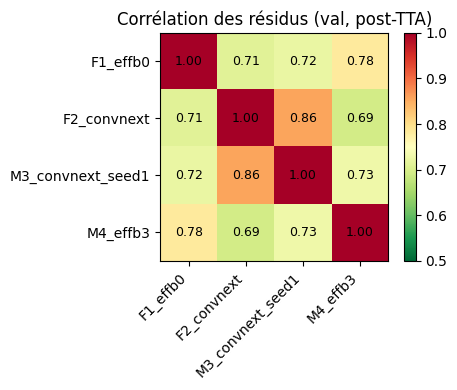

In [7]:
target = df_val.set_index('filename').loc[FILENAMES, 'FaceOcclusion'].values
residuals = pd.DataFrame({n: PREDS[n] - target for n in PREDS})
corr = residuals.corr()
print('Corrélation des résidus (1 = redondants, 0 = orthogonaux) :')
print(corr.round(3))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(5,4))
im = ax.imshow(corr.values, vmin=0.5, vmax=1.0, cmap='RdYlGn_r')
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.values[i,j]:.2f}', ha='center', va='center', fontsize=9)
plt.colorbar(im); ax.set_title('Corrélation des résidus (val, post-TTA)')
plt.tight_layout(); plt.show()


## 7. Recherche des poids optimaux d'ensemble

Avec 4 modèles, l'espace est de dimension 3 (le simplexe $\sum w_i = 1, w_i \ge 0$). On utilise `scipy.optimize.minimize` avec contrainte de somme = 1 et bornes $[0, 1]$ pour minimiser le `score` val.

⚠️ **Attention** : on minimise sur val → optimisme par construction. Pour avoir une estimation honnête, on fait aussi du **5-fold CV** sur les poids :
- Pour chaque fold, on optimise les poids sur 4/5 et on évalue sur 1/5
- Score moyen = estimation non-biaisée du gain de l'ensemble pondéré

Si l'écart entre `val direct` et `5-fold CV` est petit (< 5 %), on peut faire confiance aux poids optimisés.

In [ ]:
from scipy.optimize import minimize

names = list(PREDS.keys())
P = np.stack([PREDS[n] for n in names])    # (M, N)
gender = df_val.set_index('filename').loc[FILENAMES, 'gender'].values
y = target

def score_from_weights(w, P=P, y=y, gender=gender):
    p = (w[:,None] * P).sum(axis=0)
    df_tmp = pd.DataFrame({'pred': p, 'target': y, 'gender': gender})
    return compute_score(df_tmp)['score']

def optimize_weights(P_arr, y_arr, g_arr, x0=None):
    M = P_arr.shape[0]
    if x0 is None:
        x0 = np.ones(M) / M
    cons = [{'type': 'eq', 'fun': lambda w: w.sum() - 1.0}]
    bnds = [(0.0, 1.0)] * M
    res = minimize(
        lambda w: score_from_weights(w, P_arr, y_arr, g_arr),
        x0=x0, method='SLSQP', bounds=bnds, constraints=cons,
        options={'ftol': 1e-9, 'maxiter': 200},
    )
    return res

# 1) Optimisation directe sur 100% val 
res_full = optimize_weights(P, y, gender)
w_full = res_full.x
print('=== Poids optimaux (val 100%) ===')
for n, w in zip(names, w_full):
    print(f'  {n:22s} : {w:.3f}')
print(f'Score ensemble pondéré (val full) : {res_full.fun:.5f}')

# 2) Référence : moyenne uniforme
w_uniform = np.ones(len(names)) / len(names)
print(f'Score ensemble uniforme           : {score_from_weights(w_uniform):.5f}')

# 3) 5-fold CV : optimiser sur 4/5, évaluer sur 1/5
from sklearn.model_selection import KFold
kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_pred = np.full(len(y), np.nan)
oof_weights = []
for k, (tr, te) in enumerate(kf.split(np.arange(len(y)))):
    res_k = optimize_weights(P[:, tr], y[tr], gender[tr])
    oof_weights.append(res_k.x)
    oof_pred[te] = (res_k.x[:,None] * P[:, te]).sum(axis=0)

df_oof = pd.DataFrame({'pred': oof_pred, 'target': y, 'gender': gender})
oof_score = compute_score(df_oof)
print(f'\n=== 5-fold CV (estimation HONNÊTE du gain ensemble pondéré) ===')
print(f'Score : {oof_score["score"]:.5f} | err_F {oof_score["err_F"]:.5f} | err_M {oof_score["err_M"]:.5f} | gap {oof_score["gap"]:.5f}')

print(f'\nPoids moyens 5-fold (stabilité):')
w_mean = np.mean(oof_weights, axis=0)
w_std  = np.std(oof_weights, axis=0)
for n, m, s in zip(names, w_mean, w_std):
    print(f'  {n:22s} : {m:.3f} ± {s:.3f}')


=== Poids optimaux (val 100%) ===
  F1_effb0               : 0.381
  F2_convnext            : 0.338
  M3_convnext_seed1      : 0.281
  M4_effb3               : 0.000
Score ensemble pondéré (val full) : 0.00101
Score ensemble uniforme           : 0.00104

=== 5-fold CV (estimation HONNÊTE du gain ensemble pondéré) ===
Score : 0.00103 | err_F 0.00043 | err_M 0.00083 | gap 0.00040

Poids moyens 5-fold (stabilité):
  F1_effb0               : 0.367 ± 0.031
  F2_convnext            : 0.344 ± 0.063
  M3_convnext_seed1      : 0.263 ± 0.075
  M4_effb3               : 0.026 ± 0.037


## 8. Comparaison aux meilleures recettes Phase A

On construit un tableau qui compare :
- Phase A best : ENS_0.4F1+0.6F2_TTA = 0.001029 (chargé du CSV)
- 4 modèles solo (TTA)
- Ensemble uniforme 4 modèles
- Ensemble pondéré (poids optimisés sur 100 % val)
- Ensemble pondéré (5-fold CV honnête)

In [9]:
rows = []

# Phase A best
phaseA = pd.read_csv(EXP_DIR / 'step5_phaseA_recipes.csv').iloc[0].to_dict()
rows.append({'recipe': 'PhaseA_best (ENS_0.4F1+0.6F2_TTA)', 'score': phaseA['score'],
             'err_F': phaseA['err_F'], 'err_M': phaseA['err_M'], 'gap': phaseA['gap']})

# Solos TTA
for n in names:
    df_p = pd.DataFrame({'filename': FILENAMES, 'pred': PREDS[n]}).merge(
        df_val[['filename','FaceOcclusion','gender']].rename(columns={'FaceOcclusion':'target'}), on='filename')
    s = compute_score(df_p)
    rows.append({'recipe': f'{n}_TTA', **{k: s[k] for k in ['score','err_F','err_M','gap']}})

# Uniforme 4
p_uni = (w_uniform[:,None] * P).sum(axis=0)
s_uni = compute_score(pd.DataFrame({'pred': p_uni, 'target': y, 'gender': gender}))
rows.append({'recipe': 'ENS_4uniform_TTA', **{k: s_uni[k] for k in ['score','err_F','err_M','gap']}})

# Pondéré 100% val (optimiste)
rows.append({'recipe': 'ENS_4weighted_full_TTA',
             'score': res_full.fun,
             'err_F': compute_score(pd.DataFrame({'pred':(w_full[:,None]*P).sum(0),'target':y,'gender':gender}))['err_F'],
             'err_M': compute_score(pd.DataFrame({'pred':(w_full[:,None]*P).sum(0),'target':y,'gender':gender}))['err_M'],
             'gap':   compute_score(pd.DataFrame({'pred':(w_full[:,None]*P).sum(0),'target':y,'gender':gender}))['gap']})

# Pondéré 5-fold honnête
rows.append({'recipe': 'ENS_4weighted_5foldCV_TTA',
             'score': oof_score['score'], 'err_F': oof_score['err_F'],
             'err_M': oof_score['err_M'], 'gap': oof_score['gap']})

df_phB = pd.DataFrame(rows).sort_values('score').reset_index(drop=True)
df_phB['gap_%']      = (df_phB['gap']  / df_phB['score'] * 100).round(1)
ref = phaseA['score']
df_phB['gain_vs_PhA'] = df_phB['score'] - ref
df_phB['gain_%']      = (-df_phB['gain_vs_PhA'] / ref * 100).round(2)
df_phB.to_csv(EXP_DIR / 'step6_phaseB_recipes.csv', index=False)
df_phB


,recipe,score,err_F,err_M,gap,gap_%,gain_vs_PhA,gain_%
0,ENS_4weighted_full_TTA,0.001011,0.000426,0.000816,0.000390,38.6,-0.000018,1.74
1,PhaseA_best (ENS_0.4F1+0.6F2_TTA),0.001029,0.000435,0.000831,0.000396,38.5,0.000000,-0.00
2,ENS_4weighted_5foldCV_TTA,0.001032,0.000429,0.000831,0.000402,38.9,0.000004,-0.35
3,ENS_4uniform_TTA,0.001036,0.000435,0.000835,0.000401,38.7,0.000007,-0.67
4,F2_convnext_TTA,0.001129,0.000426,0.000895,0.000469,41.5,0.000100,-9.76
5,M3_convnext_seed1_TTA,0.001152,0.000456,0.000920,0.000464,40.3,0.000123,-11.97
6,F1_effb0_TTA,0.001189,0.000696,0.001025,0.000328,27.6,0.000160,-15.57
7,M4_effb3_TTA,0.001390,0.000729,0.001170,0.000440,31.7,0.000361,-35.11
